# 03 · Sentiment systems on natively written Twi

AfriSenti Twi test split (n = 949). The TF-IDF baseline is retrained here; transformer and NLLB outputs are loaded from `reports/predictions/` and `data/derived/`, written by `scripts/run_sentiment.py`.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, display, Markdown
pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 90)

In [2]:
from collections import Counter
from src.corpus import load_afrisenti
train, dev, test = (load_afrisenti(s) for s in ('train','dev','test'))
print({s: len(x) for s, x in zip(('train','dev','test'), (train, dev, test))})
print('test labels:', Counter(t.label for t in test))

{'train': 3481, 'dev': 388, 'test': 949}
test labels: Counter({'positive': 450, 'negative': 353, 'neutral': 146})


## Baseline retrained live

C is chosen on the dev split; the test split is used once.

In [3]:
from scripts.run_sentiment import tfidf_logreg
from src.evaluation import score
pred, info = tfidf_logreg(train, dev, test)
print(info)
saved = pd.read_csv(ROOT/'reports/predictions/all_systems_test.csv', keep_default_na=False)
print('matches saved predictions:', (saved['tfidf_logreg'] == pred).mean())
{k: round(v, 4) for k, v in score([t.label for t in test], pred).items()}

{'C_search_dev_macro_f1': {0.25: 0.5895234395234396, 0.5: 0.5885418234733303, 1.0: 0.5883367839889578, 2.0: 0.5991112186406441, 4.0: 0.5994972058801846, 8.0: 0.5940189125295507}, 'chosen_C': 4.0}
matches saved predictions: 1.0


{'accuracy': 0.6754,
 'macro_f1': 0.5925,
 'weighted_f1': 0.6693,
 'f1_negative': 0.7253,
 'f1_neutral': 0.3106,
 'f1_positive': 0.7417,
 'predicted_neutral_rate': 0.1243,
 'silent_failure_rate': 0.0959}

## All systems

In [4]:
pd.read_csv(ROOT/'reports/metrics/sentiment_results.csv', index_col=0)

,accuracy,macro_f1,weighted_f1,f1_negative,f1_neutral,f1_positive,predicted_neutral_rate,silent_failure_rate
system,,,,,,,,
majority,0.4742,0.2144,0.3051,0.0000,0.0000,0.6433,0.0000,0.0000
tfidf_logreg,0.6754,0.5925,0.6693,0.7253,0.3106,0.7417,0.1243,0.0959
english_only,0.2508,0.2432,0.2339,0.2345,0.2751,0.2201,0.8419,0.8331
xlmt,0.3351,0.3367,0.3511,0.3762,0.2793,0.3546,0.5479,0.5318
nllb_twi,0.3730,0.3728,0.3944,0.4675,0.2750,0.3758,0.5205,0.5056
nllb_aka,0.3667,0.3665,0.3862,0.4639,0.2740,0.3616,0.5153,0.5006


In [5]:
res = json.loads((ROOT/'reports/metrics/sentiment_results.json').read_text())
pd.DataFrame({s: {'macro_f1_ci95': [round(x,3) for x in r['macro_f1_ci95']],
                  'mcnemar_p_vs_baseline': r.get('mcnemar_vs_tfidf_logreg', {}).get('p_value')}
              for s, r in res['results'].items()}).T

,macro_f1_ci95,mcnemar_p_vs_baseline
majority,"[0.205, 0.224]",0.0
tfidf_logreg,"[0.559, 0.625]",None
english_only,"[0.215, 0.271]",0.0
xlmt,"[0.306, 0.367]",0.0
nllb_twi,"[0.343, 0.403]",0.0
nllb_aka,"[0.336, 0.396]",0.0


In [6]:
res['notes']

{'tfidf_logreg': {'C_search_dev_macro_f1': {'0.25': 0.5895234395234396,
   '0.5': 0.5885418234733303,
   '1.0': 0.5883367839889578,
   '2.0': 0.5991112186406441,
   '4.0': 0.5994972058801846,
   '8.0': 0.5940189125295507},
  'chosen_C': 4.0},
 'nllb_source_code': {'identical_translations': 120,
  'n': 949,
  'label_agreement_after_translation': 0.743940990516333},
 'test_label_distribution': {'negative': 353, 'neutral': 146, 'positive': 450},
 'majority_label': 'positive'}

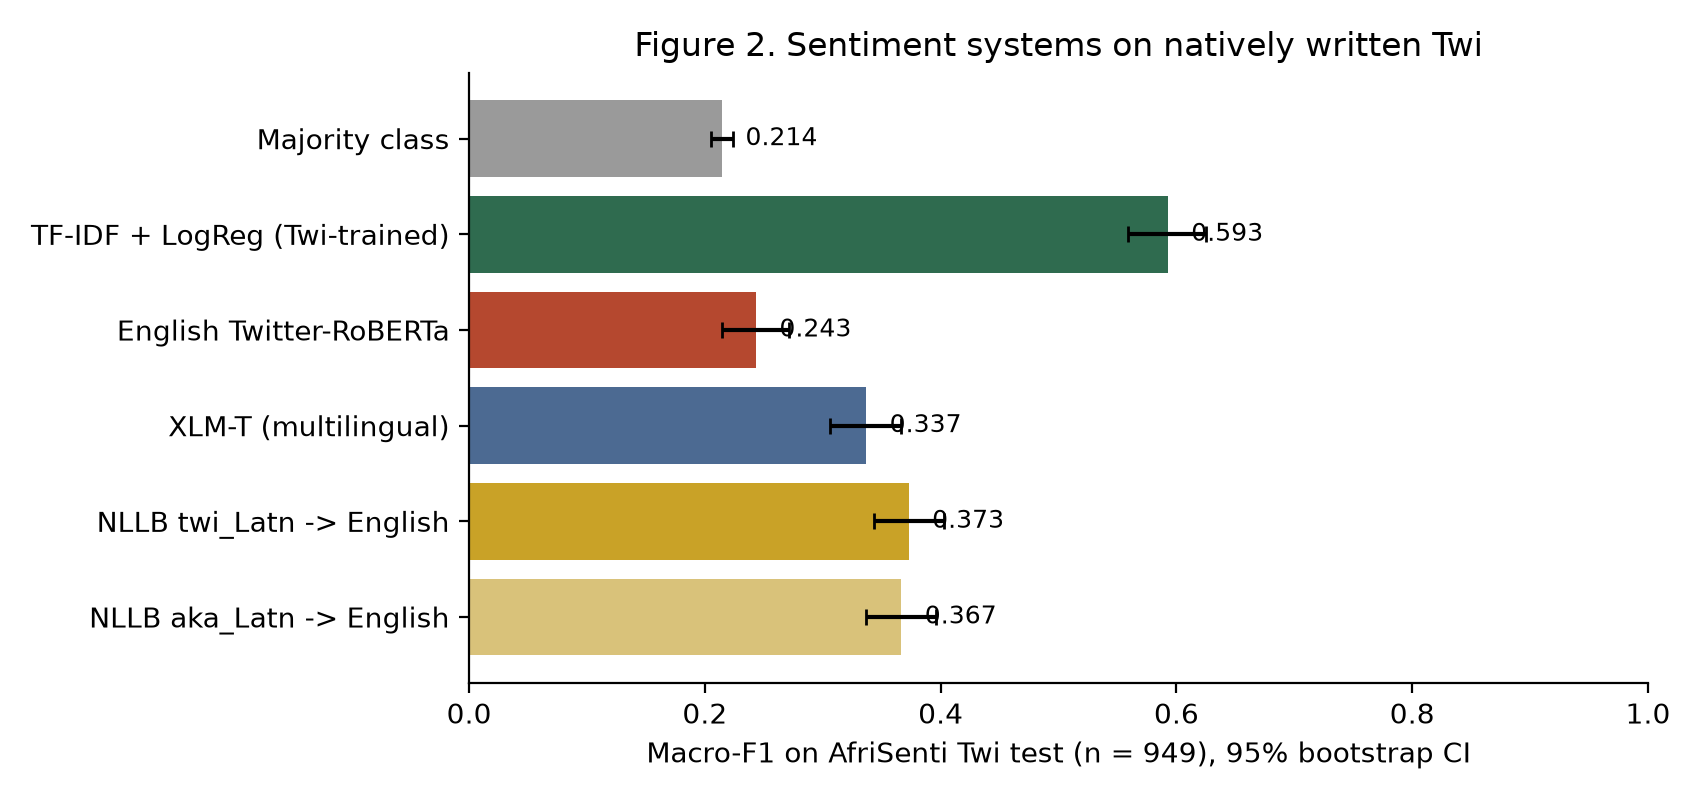

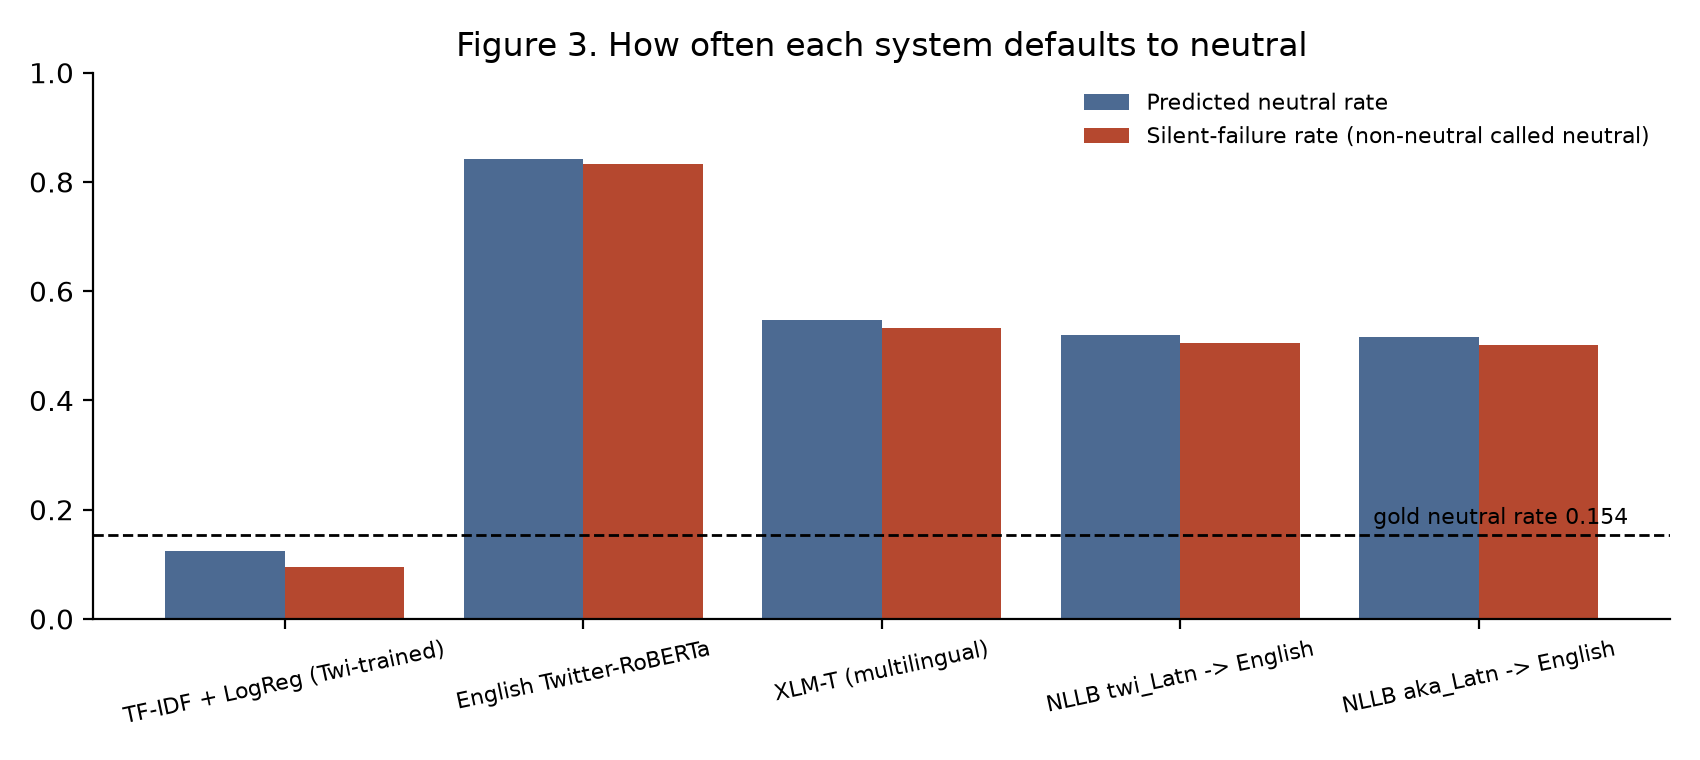

In [7]:
display(Image(str(ROOT/'reports/figures/fig2_macro_f1.png'), width=760))
display(Image(str(ROOT/'reports/figures/fig3_neutral_collapse.png'), width=760))

## Translations: twi_Latn vs aka_Latn source code

Same tweets, same model; only the declared source language changes.

In [8]:
a = pd.read_csv(ROOT/'data/derived/translations_twi_Latn.csv', keep_default_na=False)['english']
b = pd.read_csv(ROOT/'data/derived/translations_aka_Latn.csv', keep_default_na=False)['english']
pd.DataFrame({'tweet': saved['text'], 'twi_Latn -> eng': a, 'aka_Latn -> eng': b}).head(12)

,tweet,twi_Latn -> eng,aka_Latn -> eng
0,ah ka s3 prison mpo er,ah ka s3 prison er,I'm going to jail
1,slim things de3 3noaa ne wei ooo🤩🤩🤩😘😂,slim things de3 3noaa and this oh😘😂,slim things de3 3noaa and this oo😘😂
2,ampesie bi yɛ guy,a guy is a guy,an ampesie is a guy
3,😂 😂 ah daabi daabi me bo efu menua,😂 😂 ah no no no I am not afraid brother,😂 😂 ah no no no I'm not mad brother
4,hmm truly good real quick fact that go change africa but nkrumah koraa wa kunu na econ...,hmm really good real quick fact that go change africa but nkrumah totally wa husband a...,hmm really good real quick fact that go change Africa but nkrumah very much wa husband...
5,ceremonial vp nso y3di bor bra,ceremonial vp also y3di bor life,Ceremonial VP also leads a life of piety.
6,oh bro na what ado,Oh bro and what ado,Oh bro what ado
7,hyɛma no ayɛ ma ɛnam no abu so enti peter eeei wompia,I'm not sure if I'm going to be able to do it.,The man was very happy with the food.
8,ah ei pain me,Oh no pain,I'm in pain
9,eeeeiii 3ne3 mo mmoa nnipa na prostate de3 3ya,"It's not just the prostate, it's the prostate.",It's a disease of the prostate gland.
